# 01 · Data Profiling — Surabaya Coffee Listings

| | |
| --- | --- |
| **Project** | Surabaya Coffee Market Map: Structure, Saturation and White Space |
| **Author** | Laurivasya Gadhing Syahafidh |
| **Last updated** | 2026-11-16 |
| **Input** | `data/interim/places.csv` (built by `src/parse_listings.py`) |
| **Output** | Data-quality findings and the cleaning decisions for the next notebooks |

## Executive Summary

The dataset contains **17,676 places** across Surabaya. Core identification fields, such as business names are highly complete, while price information, business status, and Plus Codes have limited coverage. The three main data problems are diverse business categories, repeated business names that make chain identification difficult, and incomplete location information. Review counts are also highly concentrated, with the top 10% of places accounting for 87.6% of all reviews. Next, we need to define keep-or-drop rules, identify relevant coffee businesses, resolve location gaps, and analyze customer attention within the filtered dataset.

## 1. Context and objective

The project maps Surabaya's coffee market for a specialty coffee chain choosing where to open next. Before any analysis, this notebook checks whether the listing table can support it.

**Objective:** measure the size, completeness and validity of the table, and decide what must be cleaned, filtered or located before analysis.

**Unit of analysis:** one row = one listed place (unique name + address).

## 2. Profiling questions

1. How large is the table, and are the column types correct?
2. How complete is each column?
3. Are there exact duplicates or likely duplicate places?
4. Which categories are in scope for a coffee study?
5. How are review counts distributed, and are there invalid or extreme values?
6. How much location information does each place have?

## 3. Data source and dictionary

**Source:** Google local search results for coffee-related queries in each of Surabaya's 153 kelurahan, exported 14–16 Nov 2026 (152 files, 28,527 rows). `src/parse_listings.py` removed 3,211 junk rows and merged 7,640 duplicate rows. Raw exports are kept unchanged in `data/raw/listings_surabaya/` and are not published.

| Column | Description | Expected type |
| --- | --- | --- |
| `place_key` | Hash of name + address; unique row ID | text |
| `name` | Listed business name | text |
| `category` | Category shown in the listing | text |
| `reviews` | Number of reviews; 0 = "No reviews"; empty = not shown | integer |
| `address` | Address line as shown | text |
| `plus_code` | Location code extracted from the address, if present | text |
| `price_band` | Price range per person, if shown | text |
| `status_at_collection` | Open/closed label at the moment of collection | text |
| `n_search_batches` | Number of export files the place appeared in | integer |

## 4. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
PLACES_FILE = PROJECT_ROOT / "data" / "interim" / "places.csv"
IMAGES_DIR = PROJECT_ROOT / "images"

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
places = pd.read_csv(PLACES_FILE, dtype={"reviews": "Int64"})
places.sample(5, random_state=42)

,place_key,name,category,reviews,address,plus_code,price_band,status_at_collection,n_search_batches
14874,3150872c710e,Warkop Portal,Coffee shop,3,Jl. Tambak Medokan Ayu No.14 Kavling # A,NaN,NaN,NaN,1
5125,feb1ba24416e,jus ibu RO,Coffee shop,2,Jl. Kembang Jepun No.145 Blk B27,NaN,NaN,NaN,1
1453,b623b899a039,bila,Coffee shop,0,"Jl. Jatisrono IV No.8-B, RT.011/RW.14",NaN,NaN,NaN,1
6070,e2a288220a9a,KEDAI TOKO KOPI ARA,Coffee shop,129,"Kedai ARA, Jl. Nusa Indah",NaN,Rp 1–25.000,NaN,4
16552,a5448da6a14b,Warung Kopi 83,Coffee shop,7,"QJ2R+9Q3 UD Al'inayah, Jl. Raya Sememi Jaya",QJ2R+9Q3,NaN,NaN,1


## 5. Structure and data types

Confirms the table loaded as expected: 17,676 rows and the nine columns in the dictionary.

In [3]:
print(f"Rows: {len(places):,} | Columns: {places.shape[1]}")
places.dtypes.to_frame("dtype")

Rows: 17,676 | Columns: 9


,dtype
place_key,object
name,object
category,object
reviews,Int64
address,object
plus_code,object
price_band,object
status_at_collection,object
n_search_batches,int64


>**Finding 1 -** The dataset contains **17,676 records** and 9 columns. The columns `place_key`, `name`, `category`, `address`, `plus_code`, `price_band`, and `status_at_collection` are stored as `object` data types, while `reviews` and `n_search_batches` are stored as `integer` data types.

## 6. Completeness

In [4]:
completeness = (places.notna().mean() * 100).round(1).sort_values(ascending=False)
completeness.to_frame("% filled")

,% filled
place_key,100.0
name,100.0
n_search_batches,100.0
category,99.9
address,99.5
reviews,87.8
plus_code,12.6
price_band,11.0
status_at_collection,4.7


> **Finding 2 —** `Reliable` (>85%): place_key (100%), name (100%), n_search_batches (100%), category (99.9%), address (99.5%), and reviews (87.8%). `Partial` (10–85%): plus_code (12.6%) and price_band (11.0%). `Too sparse` (<10%): status_at_collection (4.7%).

## 7. Duplicates

In [5]:
print("Duplicate place_key:", places["place_key"].duplicated().sum())

name_counts = places["name"].str.lower().str.strip().value_counts()
print("Names used by more than one row:", (name_counts > 1).sum())
name_counts.head(20).to_frame("rows")

Duplicate place_key: 0
Names used by more than one row: 758


,rows
name,
point coffee,64
alfamart,22
warkop,20
warkop barokah,19
indomaret,19
warung kopi,16
warkop pojok,15
warkop 99,14
warkop ijo,13


>**Finding 3 —** Repeated names do not always represent chain outlets. Names like Point Coffee (64 records), Alfamart (22), and Indomaret (19) may represent real chains, while Warkop (20) and Warung Kopi (16) are generic names. 0 duplicates IDs, and 758 names used by more than one row

## 8. Categories

In [6]:
category_counts = places["category"].value_counts()
print("Distinct categories:", len(category_counts))
category_counts.head(25).to_frame("places")

Distinct categories: 452


,places
category,
Coffee shop,10850
Cafe,2122
Restaurant,517
Convenience store,259
Noodle Shop,206
Indonesian,168
Bakery,158
Ice Cream,151
Diner,144


In [7]:
places[places["category"] == "Espresso bar"]

,place_key,name,category,reviews,address,plus_code,price_band,status_at_collection,n_search_batches
1308,40d165472795,BDF (Bring Da Fun ) Kopi Bajaj Surabaya,Espresso bar,9,"Pos Bloc Surabaya, Jl. Kebon Rojo No.10",NaN,Rp 1–25.000,NaN,2
1403,b9ebb162bf94,Benowo Kopi,Espresso bar,342,"Surakarta City, Central Java",NaN,NaN,NaN,3
1660,c17a4612b086,Buono Kopi #2,Espresso bar,3,Jl. Karang Menjangan No.131,NaN,NaN,NaN,1
1926,3deebd4c970a,Cafe SIGU,Espresso bar,48,Jl. Raya Simo Gunung No.72A,NaN,NaN,NaN,1
2468,271be09dd243,Crab ( Coffeeshop & Barbershop ),Espresso bar,23,Jl. Dukuh Kupang Bar. XVI No.27A,NaN,NaN,NaN,1
2575,8880312cd239,D'warry,Espresso bar,<NA>,Jl. Wonorejo I No.2a,NaN,NaN,NaN,1
2976,aaf026efa516,DIMAS COFFE 69,Espresso bar,22,Jl. Gadukan Rukun No.92,NaN,NaN,NaN,1
2977,b18ed62bfd5c,Dimas Coffee,Espresso bar,<NA>,"Jl. Gb. Kertajaya VIII B No.8 004, RT./RW/RW.: 003",NaN,NaN,NaN,2
3057,f63527956bdd,DOGER KITA,Espresso bar,<NA>,Jl.Petemon II No.57,NaN,NaN,NaN,1
3098,33658a15b7c6,Dream Warkop,Espresso bar,9,Jl. Petemon III No.195,NaN,NaN,NaN,1


> **Finding 4 —** Coffee-related categories 73.4% are Coffee shop or Cafe; adding Espresso bar, Coffee store and Coffee stand gives 74.2%. Other categories should be reviewed before removal by checking whether business names contain keywords such as "kopi", "coffee", "cafe", or "kafe". Large non-coffee categories, such as `Restaurant` and `Convenience store`, require a keep-or-drop decision. Convenience stores may matter because some sell ready-to-drink coffee or operate coffee corners. However, they should only be retained if they are relevant to the study's definition of a coffee business.

## 9. Review counts

In [8]:
print("Negative values:", (places["reviews"] < 0).sum())
places["reviews"].describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(0).to_frame("reviews")

Negative values: 0


,reviews
count,15513.0
mean,238.0
std,1528.0
min,0.0
50%,9.0
75%,59.0
90%,327.0
99%,4288.0
max,90000.0


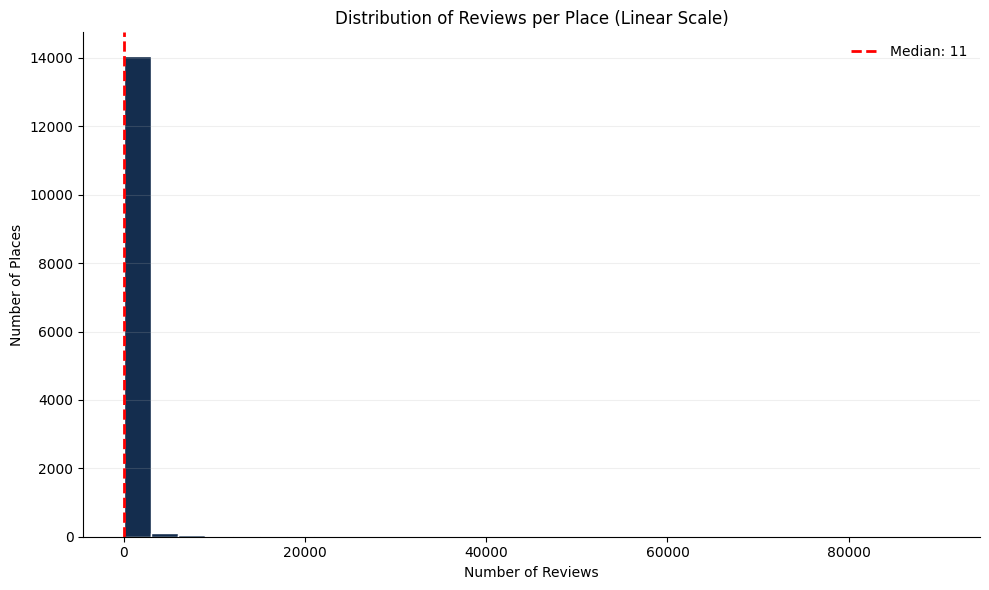

In [9]:
reviewed = places.loc[places["reviews"] > 0, "reviews"].astype(float)
median_reviews = reviewed.median()

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    reviewed,
    bins=30,
    color="#142D4E",
    edgecolor="white"
)

ax.axvline(
    median_reviews,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_reviews:,.0f}"
)

ax.set_title("Distribution of Reviews per Place (Linear Scale)")
ax.set_xlabel("Number of Reviews")
ax.set_ylabel("Number of Places")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

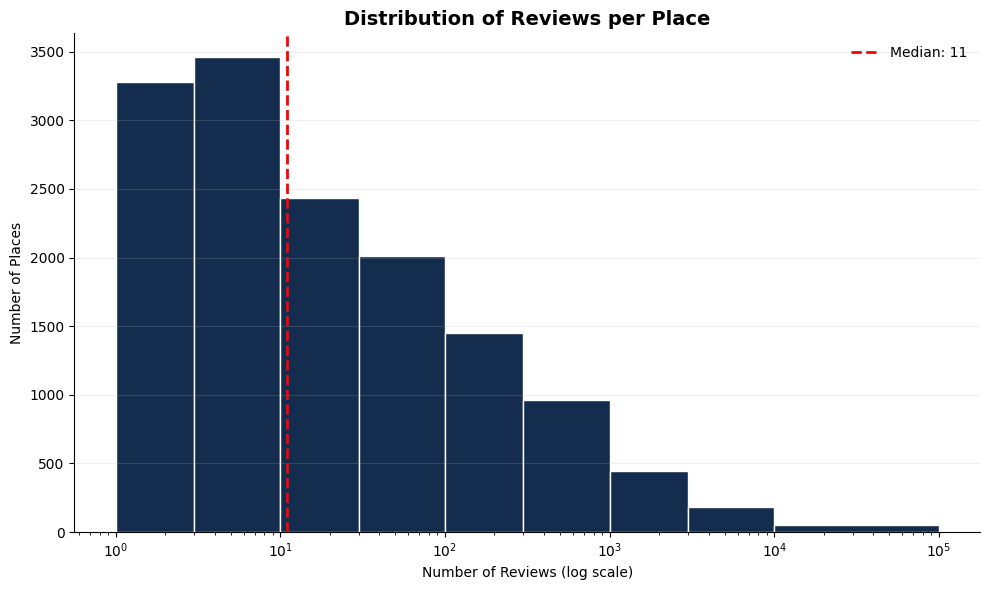

In [10]:
reviewed = places.loc[places["reviews"] > 0, "reviews"].astype(float)
median_reviews = reviewed.median()
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    reviewed,
    bins=[1, 3, 10, 30, 100, 300, 1_000, 3_000, 10_000, 100_000],
    color="#142D4E",
    edgecolor="white",
    linewidth=1
)
ax.axvline(
    median_reviews,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_reviews:,.0f}"
)

ax.set_xscale("log")
ax.set_title("Distribution of Reviews per Place", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of Reviews (log scale)")
ax.set_ylabel("Number of Places")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    IMAGES_DIR / "01_review_distribution_log_scale.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [11]:
sorted_reviews = places["reviews"].dropna().sort_values(ascending=False)
top_n = int(len(sorted_reviews) * 0.10)
top_10_share = sorted_reviews.head(top_n).sum() / sorted_reviews.sum()

print(f"Top 10% share of total reviews: {top_10_share:.1%}")

Top 10% share of total reviews: 87.6%


In [12]:
places.nlargest(15, "reviews")[["name", "category", "reviews"]]

,name,category,reviews
11378,Tunjungan Plaza,Shopping mall,90000
11270,Tomoko Sushi - Royal Plaza,Japanese,46000
4407,Hartono BG Junction,Electronics store,42000
17525,WTC Surabaya,Shopping mall,39000
7335,Mall Ciputra World Surabaya,Shopping mall,33000
8465,Pakuwon Mall Surabaya,Shopping mall,33000
8579,Pasar Atom,Market,31000
8819,PLASA MARINA SURABAYA,Shopping mall,31000
4409,Hartono Kertajaya Indah,Electronics store,30000
3646,Food Junction Grand Pakuwon,Food court,25000


> **Finding 5 —** The top 10% of places account for **87.6% of total reviews**, showing that reviews are highly concentrated among a small number of businesses. However, the 15 most-reviewed places are not coffee shops. Therefore, we need to filter the dataset to coffee-related businesses before analyzing review counts to avoid misleading results. The median is **9 reviews** and 90% of places have 327 or fewer.

## 10. Location information

In [13]:
location_type = pd.Series("other text", index=places.index)
location_type[places["address"].str.match(r"(?i)^(jl|jalan)\b", na=False)] = "street address"
location_type[places["plus_code"].notna()] = "plus code (exact)"
location_type[places["address"] == "Surabaya, East Java"] = "city only"
location_type[places["address"].isna()] = "no address"

location_summary = location_type.value_counts().to_frame("places")
location_summary["% of places"] = (location_summary["places"] / len(places) * 100).round(1)
location_summary

,places,% of places
street address,11699,66.2
other text,2971,16.8
plus code (exact),2233,12.6
city only,680,3.8
no address,93,0.5


In [14]:
no_address = places.loc[
    location_type == "no address",
    ["name", "category", "address", "plus_code"]
]

display(no_address)

,name,category,address,plus_code
395,Ampel,"Surabaya, East Java",NaN,NaN
542,Angkringan J K K II,Coffee shop,NaN,NaN
563,Angkringan Kampung,Coffee shop,NaN,NaN
721,Angkringan Soimah,Coffee shop,NaN,NaN
843,AREK Coffee & Eatery,Coffee shop,NaN,NaN
...,...,...,...,...
17180,Warung Pojok,Coffee shop,NaN,NaN
17454,West Perak,"Surabaya, East Java",NaN,NaN
17482,Wisco Drink n Snack,Coffee store,NaN,NaN
17537,Xiang Rui Kopitiam,Coffee shop,NaN,NaN


In [15]:
city_only = places.loc[
    location_type == "city only",
    ["name", "category", "address", "plus_code"]
]

display(city_only)

,name,category,address,plus_code
69,(WARKOPI) Warung Konco Ngopi,Coffee shop,"Surabaya, East Java",NaN
85,2 DERAJAT COFFEE,Coffee shop,"Surabaya, East Java",NaN
97,3phase Sub,Coffee shop,"Surabaya, East Java",NaN
128,A,Coffee shop,"Surabaya, East Java",NaN
146,Abijuna Cafe,Cafe,"Surabaya, East Java",NaN
...,...,...,...,...
17629,Zao An Kopitiam,Coffee shop,"Surabaya, East Java",NaN
17643,Zerøgram. - Tunjungan,Coffee shop,"Surabaya, East Java",NaN
17651,ZIMEL COFFEE,Coffee shop,"Surabaya, East Java",NaN
17654,Zomer Cafe,Cafe,"Surabaya, East Java",NaN


> **Finding 6 —** Approximately **78.8% of places have street-level addresses or exact Plus Codes**, making them potentially useful for geographic analysis. However, **4.3% have only city-level information or no address**, so they cannot be precisely located. Business categories are also diverse, so we need to define keep-or-drop rules before filtering the dataset and completing missing address information.

## 11. Conclusions and next steps

| Issue found | Decision | Handled in |
| --- | --- | --- |
| Missing or incomplete coordinates | Locate using Plus Codes, name matching, and street geocoding | `02_locating_places.ipynb` |
| Non-coffee categories | Apply keep-or-drop rules to retain relevant coffee businesses | `03_segment_classification.ipynb` |
| Chains and generic names | Distinguish actual chains from generic business names | `03_segment_classification.ipynb` |
| Skewed review counts | Filter to coffee-related businesses before analyzing review counts | `04_market_structure.ipynb` |
